# Validated two-fin electromagnetic engine · CUDA FDTD + GPU RCWA

**Goal:** characterize one periodically repeated Al₂O₃ two-fin meta-atom at **633 nm**, without shape optimization.

The notebook is the entry point; the small `.py` modules handle the numerical work. Both backends use the **same polygon union**, material definitions, and laboratory-coordinate polarization basis.

We seek the complex, power-normalized **four-port-channel** scattering matrix

$$S=\begin{pmatrix}R_{11}&T_{12}\\T_{21}&R_{22}\end{pmatrix},$$

with channel order `(bottom x, bottom y, top x, top y)`. All four propagating channels are included at normal incidence (the 400 nm period is below the air/silica diffraction thresholds).

**Full complex phase is preserved**, including the common phase of each Jones block. The characterization below distinguishes measured channel phases, a determinant-based common-phase convention, and optional changes of *reference planes*; it does not discard propagation phase.

> **Accuracy boundary:** FDTD uses scalar volume-fraction subpixel averaging, **not** a full tensor Yee-staggered subpixel formulation. RCWA uses finite Fourier order. The physical solver results must pass runtime checks on your machine before their phases are trusted.

## 1. Configuration and prerequisites

GPU backends require CUDA-capable PyTorch, [`flaport/fdtd`](https://github.com/flaport/fdtd) and [`torcwa`](https://github.com/kch3782/torcwa). Both were checked against their documented APIs; runtime integration requires your CUDA workstation.

In [ ]:
# Shared engines live in ../core (see ../PROJECTS.md). Run with the notebook folder as cwd.
import sys; from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / 'core').resolve()))

In [1]:
from dataclasses import replace
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from twofin import Config, write_gds, draw_geometry, stokes
from engine_geometry import coverage, epsilon_map, plot_geometry
import engine_fdtd
from engine_fdtd import Settings as FDTDSettings, solve as fdtd_solve
from engine_rcwa import Settings as RCWASettings, solve as rcwa_solve
from engine_validate import (fresnel, metrics, check, display_matrix,
    print_polarization_modes, plot_poincare, eigenstate_path,
    pancharatnam_phase, plot_path, quality_gates, change_reference_planes,
    fresnel_yee, fdtd_to_continuum_planes, scattering_comparison, yee_wavenumber)

OUT = Path('results'); OUT.mkdir(exist_ok=True)
RUN_RCWA = True
RUN_FDTD = True
RUN_CONVERGENCE = True     # Expensive additional solves
RUN_TRANSPORT = True       # Additional RCWA geometries
FORCE_FDTD = False
CAPTURE_EFIELD = True       # Retain flat/two-fin Ex snapshots in FDTD launches

print("FDTD engine source:", engine_fdtd.__file__)
if CAPTURE_EFIELD and getattr(engine_fdtd, "SNAPSHOT_SCHEMA_VERSION", 0) < 2:
    raise RuntimeError("Old engine_fdtd module is loaded. Replace engine_fdtd.py and restart the notebook kernel.")

cfg = Config(
    wavelength=0.633,
    period=0.400,
    height=0.350,
    fin_length=0.340,
    fin_width=0.050,
    global_deg=0.0,
    relative_deg=90.0,
    center1=(0.0, -0.110),
    center2=(0.110, 0.0),
)
cfg.validate()
fd_settings = FDTDSettings(dx_nm=20., samples=5, backend='torch.cuda.float32')
rc_settings = RCWASettings(order=4, raster=160, samples=3, device='cuda')
print('Wavelength (nm):', cfg.wavelength*1000)
print('Fin angles (deg):', cfg.global_deg, cfg.global_deg + cfg.relative_deg)
print('FDTD:', fd_settings)
print('RCWA:', rc_settings)

FDTD engine source: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/engine_fdtd.py
Wavelength (nm): 633.0
Fin angles (deg): 0.0 90.0
FDTD: Settings(dx_nm=20.0, samples=5, pml_um=0.3, bottom_um=1.2, top_um=1.2, source_bottom=-0.9, source_top_offset=0.9, port_bottom=-0.52, port_top_offset=0.52, settle_cycles=14, measure_cycles=6, ramp_cycles=4, backend='torch.cuda.float32')
RCWA: Settings(order=4, raster=160, samples=3, device='cuda', precision='complex64')


## 2. Continuous geometry, GDS and subpixel map

The GDSII writer merges touching/overlapping polygons before export. The geometry rasterizer also takes their Boolean union, so overlap **never doubles the material permittivity**.

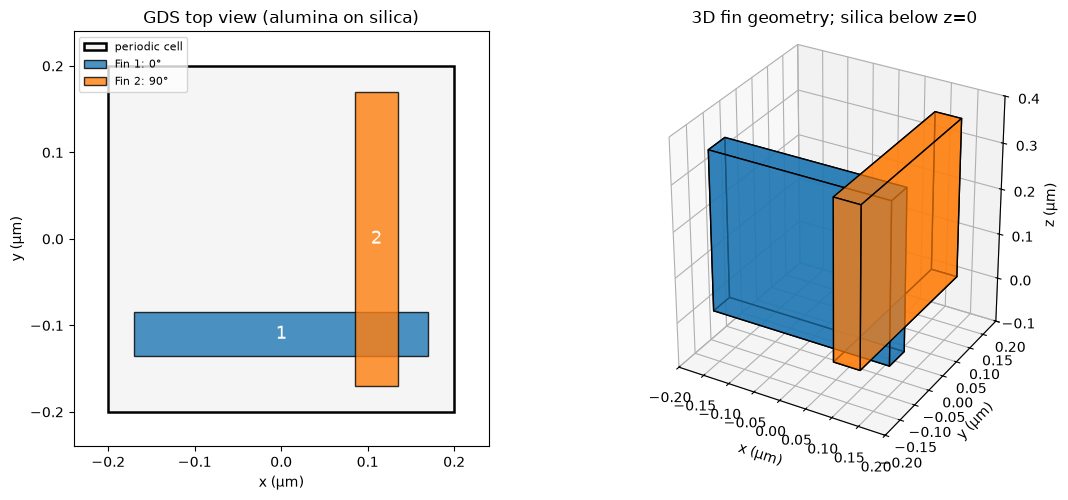

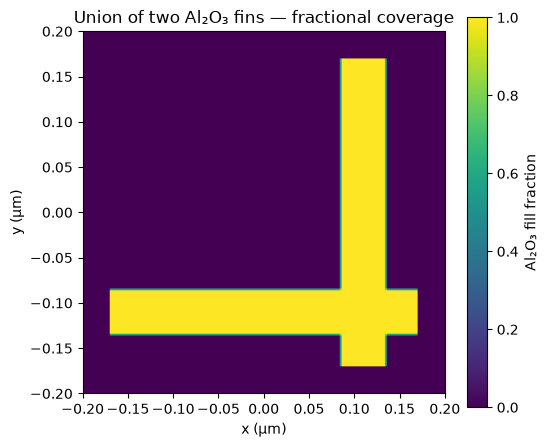

Discretized size: (20, 20, 168) Yee cells: 67200
Fill fraction min/max: 0.0 1.0


In [2]:
cfg.validate()
write_gds(cfg, OUT/'twofin_unit_cell.gds')
fig = draw_geometry(cfg, OUT/'geometry.png')
plt.show()
fig = plot_geometry(cfg)
plt.show()
eps,spec = epsilon_map(cfg,dx_nm=fd_settings.dx_nm,samples=fd_settings.samples,
    bottom_um=fd_settings.bottom_um,top_um=fd_settings.top_um,pml_um=fd_settings.pml_um)
print('Discretized size:',eps.shape, 'Yee cells:',eps.size)
print('Fill fraction min/max:',spec['fill'].min(),spec['fill'].max())

## 3. Fresnel benchmark (no numerical solver)

Both media are lossless and nondispersive in this first version: $n_\mathrm{silica}=1.46$, $n_\mathrm{Al_2O_3}=1.76$. The analytical interface is at $z=0$; complex propagation to the FDTD monitor planes is included.

In [3]:
port_b = float(spec['z'][np.argmin(abs(spec['z']-fd_settings.port_bottom))])
port_t = float(spec['z'][np.argmin(abs(spec['z']-(cfg.height+fd_settings.port_top_offset)))])
ports = (port_b,port_t)
S_analytic = fresnel(cfg,*ports)
display_matrix(S_analytic,'Analytical bare-interface S')
print(metrics(S_analytic))

# Quantify the phase accumulation created by the discrete Yee dispersion.
S_yee = fresnel_yee(cfg,*ports,fd_settings.dx_nm/1000)
print('Yee numerical dispersion prediction |S_Yee - S_Fresnel| max:',
      np.max(np.abs(S_yee-S_analytic)))
for n,label in ((1.0,'air'),(cfg.n_sub,'silica')):
    k0=2*np.pi*n/cfg.wavelength
    kn=yee_wavenumber(cfg,fd_settings.dx_nm/1000,n)
    print(f'{label}: k0={k0:.6f}, k_Yee={kn:.6f} rad/µm, Δk={kn-k0:+.6f}')

Analytical bare-interface S: bottom(x,y), top(x,y)

-0.17588+0.06349j  -0.00000+0.00000j  -0.80605-0.56153j  +0.00000-0.00000j
-0.00000+0.00000j  -0.17588+0.06349j  +0.00000-0.00000j  -0.80605-0.56153j
-0.80605-0.56153j  +0.00000-0.00000j  +0.00139+0.18699j  +0.00000+0.00000j
+0.00000-0.00000j  -0.80605-0.56153j  +0.00000+0.00000j  +0.00139+0.18699j

Magnitude:
[[0.18699 0.      0.98236 0.     ]
 [0.      0.18699 0.      0.98236]
 [0.98236 0.      0.18699 0.     ]
 [0.      0.98236 0.      0.18699]]
Phase (deg):
[[ 160.15  180.   -145.14   -0.  ]
 [ 180.    160.15   -0.   -145.14]
 [-145.14   -0.     89.57    0.  ]
 [  -0.   -145.14    0.     89.57]]
{'reciprocity_max': 0.0, 'unitarity_max': 2.776319786554118e-17, 'passivity_lambda_max': 1.0, 'worst_power_error': 0.0}
Yee numerical dispersion prediction |S_Yee - S_Fresnel| max: 0.03199158730295357
air: k0=9.926043, k_Yee=9.937065 rad/µm, Δk=+0.011022
silica: k0=14.492023, k_Yee=14.535379 rad/µm, Δk=+0.043356


## 4. Independent RCWA: bare interface then two fins

TORCWA uses two polarization channels on each side and includes multiple **internal** Fourier harmonics. We extract only the propagating zeroth-order channels for this subwavelength lattice. The RCWA plane references are propagated analytically to the FDTD port positions.

In [4]:
rc = None
if RUN_RCWA:
    rc_bare = rcwa_solve(cfg,rc_settings,ports=ports,bare=True)
    print('RCWA bare interface compared with Fresnel:')
    scattering_comparison(rc_bare['S'], S_analytic, 'RCWA bare vs physical Fresnel')
    check(rc_bare['S'],reference=rc_bare['S'],analytic=S_analytic)
    rc = rcwa_solve(cfg,rc_settings,ports=ports,bare=False)
    display_matrix(rc['S'],'RCWA two-fin S')
    print('RCWA two-fin diagnostics:')
    check(rc['S'])
    print('RCWA elapsed:', round(rc['elapsed_s'],2),'s')

RCWA bare interface compared with Fresnel:
RCWA bare vs physical Fresnel: max |ΔS|=0.000000, max ||S|-|Sref||=0.000000, max |Δphase| (|Sref|>0.05)=0.000°
reciprocity_max            : 5.96046e-08
unitarity_max              : 7.09596e-08
passivity_lambda_max       : 1
worst_power_error          : 7.09596e-08
flat_vs_fresnel_max        : 5.7968e-08
flat_unitarity_max         : 7.09596e-08
RCWA two-fin S: bottom(x,y), top(x,y)

-0.11325-0.03319j  +0.00093-0.00018j  -0.37979-0.91750j  +0.00535-0.00233j
+0.00093-0.00018j  -0.11324-0.03319j  +0.00535-0.00232j  -0.37976-0.91751j
-0.37979-0.91750j  +0.00535-0.00233j  -0.05665+0.10352j  -0.00043-0.00119j
+0.00535-0.00232j  -0.37976-0.91751j  -0.00043-0.00119j  -0.05665+0.10352j

Magnitude:
[[0.11801 0.00094 0.99299 0.00584]
 [0.00095 0.11801 0.00583 0.993  ]
 [0.99299 0.00584 0.11801 0.00127]
 [0.00583 0.993   0.00127 0.118  ]]
Phase (deg):
[[-163.67  -11.16 -112.49  -23.52]
 [ -10.88 -163.66  -23.39 -112.48]
 [-112.49  -23.51  118.69 -109.91]
 

## 5. CUDA FDTD: discrete-dispersion-aware scattering validation

The 20 nm Yee grid has a slightly different free-space and silica wave number from the continuum. The original Fresnel phase comparison therefore contains a **predictable numerical propagation error**, even when the interface and modal extraction are otherwise correct.

We print the original discrepancy, compare against a **discrete-phase Fresnel prediction without fitting**, and rephase the FDTD output at the original monitor locations to allow physical comparison with RCWA. This removes only homogeneous-region propagation error, *not* interface or geometry discretization error. The raw `S` is always retained.

With `CAPTURE_EFIELD=True`, the FDTD engine additionally retains instantaneous central $x$–$z$ plane $E_x$ snapshots from the flat and two-fin bottom-$x$ launches. These are captured during the **existing eight scattering solves**, not separate simulations. An older cache without fields will be rebuilt once if snapshots are requested. Applying the accompanying `engine_fdtd.patch` is necessary.
With `CAPTURE_EFIELD=True`, two bottom-incident x-polarized runs retain real instantaneous `E_x` cross-sections. If a scattering-only cache already exists, the engine reuses `S` and performs only the two field captures. Reload the Python kernel after replacing `engine_fdtd.py`.


In [5]:
fd = None
if RUN_FDTD:
    fd = fdtd_solve(cfg,fd_settings,cache=OUT,force=FORCE_FDTD,
                    snapshot=CAPTURE_EFIELD)
    if CAPTURE_EFIELD:
        required = ('snapshot_flat_xz', 'snapshot_twofin_xz')
        missing = [key for key in required if key not in fd]
        if missing:
            raise RuntimeError(f'FDTD engine omitted {missing}; source: {engine_fdtd.__file__}')
        print('Captured paired field maps:',
              {key: np.asarray(fd[key]).shape for key in required})
    print('FDTD bare interface: continuum benchmark (phase discrepancy expected)')
    scattering_comparison(fd['S_flat'], S_analytic, 'Measured FDTD vs physical Fresnel')
    print('FDTD bare interface: Yee-dispersion benchmark (no fitted phases)')
    scattering_comparison(fd['S_flat'], fd['S_fresnel_yee'], 'Measured FDTD vs Yee Fresnel')
    print('FDTD bare interface: converted to continuum monitor-plane phases')
    scattering_comparison(fd['S_flat_phase_aligned'], S_analytic,
                          'De-embedded FDTD vs physical Fresnel')
    display_matrix(fd['S_phase_aligned'],'FDTD two-fin S (homogeneous propagation phase corrected)')
    print('FDTD two-fin diagnostics:')
    check(fd['S_phase_aligned'])
    print('Maximum relative difference between acquisition halves:',
          max(fd['acquisition_residuals']))
    print('FDTD total GPU simulation time (s):', round(sum(fd['durations_s']),2))
    print('Peak PyTorch CUDA allocation (MiB):', np.nanmax(fd['cuda_peak_mb']))
    quality_gates(fd['S_phase_aligned'],flat=fd['S_flat_phase_aligned'],analytic=S_analytic,
                  other=(rc['S'] if rc is not None else None),
                  acq=fd['acquisition_residuals'])

FDTD reference / bottom / x
FDTD reference / bottom / y
FDTD reference / top / x
FDTD reference / top / y
FDTD two-fin / bottom / x
FDTD two-fin / bottom / y
FDTD two-fin / top / x
FDTD two-fin / top / y
FDTD bare-interface continuum Fresnel error: 0.0320799451426102
FDTD bare-interface Yee-phase Fresnel error: 0.0026568723904330247
FDTD structure validation: {'reciprocity_max': 0.004668478520252611, 'unitarity_max': 0.0045950306880885305, 'passivity_lambda_max': 1.003623035674339, 'worst_power_error': 0.004595030688088642}
Captured paired field maps: {'snapshot_flat_xz': (20, 168), 'snapshot_twofin_xz': (20, 168)}
FDTD bare interface: continuum benchmark (phase discrepancy expected)
Measured FDTD vs physical Fresnel: max |ΔS|=0.032080, max ||S|-|Sref||=0.002657, max |Δphase| (|Sref|>0.05)=2.623°
FDTD bare interface: Yee-dispersion benchmark (no fitted phases)
Measured FDTD vs Yee Fresnel: max |ΔS|=0.002657, max ||S|-|Sref||=0.002657, max |Δphase| (|Sref|>0.05)=0.065°
FDTD bare interfa

### 5a. Instantaneous electric-field cross sections

Compare $E_x(x,z,t_\mathrm{final})$ for the flat silica/air interface and the two-fin cell under the **same bottom-side $x$-polarized source**. These fields are real snapshots (not $|E|$), with one shared color scale. Gray bands mark the PML. The plot requires FDTD snapshots; scattering-only cached matrices cannot reconstruct spatial near fields.

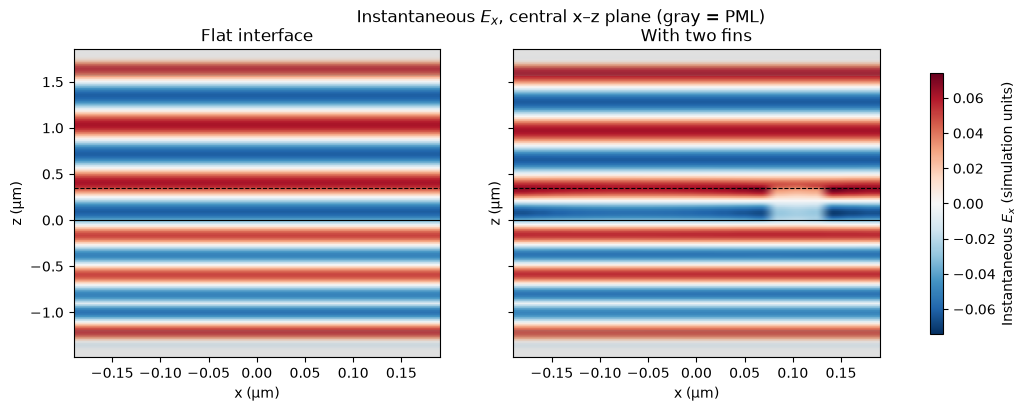

In [6]:
if fd is not None and CAPTURE_EFIELD:
    x, z = np.asarray(spec['x']), np.asarray(spec['z'])
    flat = np.asarray(fd['snapshot_flat_xz'])
    fins = np.asarray(fd['snapshot_twofin_xz'])
    if flat.shape != (len(x),len(z)) or fins.shape != flat.shape:
        raise ValueError(f'Field/simulation grid mismatch: {flat.shape}, {fins.shape}')
    vmax = max(np.max(abs(flat)), np.max(abs(fins)), 1e-12)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
    for ax, field, title in zip(axes, (flat, fins), ('Flat interface', 'With two fins')):
        im = ax.imshow(field.T, origin='lower', aspect='auto', cmap='RdBu_r',
                       vmin=-vmax, vmax=vmax, extent=[x[0],x[-1],z[0],z[-1]])
        ax.axhspan(z[0], z[spec['npml']], color='gray', alpha=.18)
        ax.axhspan(z[-spec['npml']], z[-1], color='gray', alpha=.18)
        ax.axhline(0, color='black', lw=.8)
        ax.axhline(cfg.height, color='black', lw=.8, ls='--')
        ax.set(xlabel='x (µm)', ylabel='z (µm)', title=title)
    fig.colorbar(im, ax=axes, label='Instantaneous $E_x$ (simulation units)', shrink=.85)
    fig.suptitle('Instantaneous $E_x$, central x–z plane (gray = PML)')
    plt.show()
elif fd is None:
    print('E-field plots require RUN_FDTD=True.')
else:
    print('Set CAPTURE_EFIELD=True to retain the E-field snapshots.')

## 6. Redundant solver comparison, with consistent phase conventions

Check the RCWA bare interface independently first. Compare both the original and the dispersion-aligned FDTD matrices; do not interpret a phase-reference mismatch as polarization physics. Large residual discrepancies after de-embedding still require FDTD grid and RCWA-order convergence, with possible RCWA factorization and scalar subpixel errors.

Before de-embedding:
Raw FDTD vs RCWA: max |ΔS|=0.127965, max ||S|-|Sref||=0.016667, max |Δphase| (|Sref|>0.05)=13.041°
After removing homogeneous-region Yee numerical phase:
Aligned FDTD vs RCWA: max |ΔS|=0.099465, max ||S|-|Sref||=0.016667, max |Δphase| (|Sref|>0.05)=10.408°


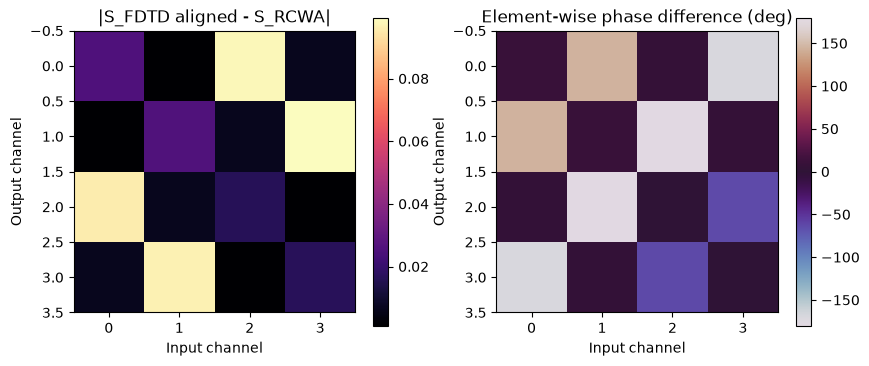

In [7]:
if rc is not None and fd is not None:
    print('Before de-embedding:')
    scattering_comparison(fd['S'],rc['S'],'Raw FDTD vs RCWA')
    print('After removing homogeneous-region Yee numerical phase:')
    scattering_comparison(fd['S_phase_aligned'],rc['S'],'Aligned FDTD vs RCWA')
    delta = fd['S_phase_aligned']-rc['S']
    fig,axs=plt.subplots(1,2,figsize=(10,4))
    im0=axs[0].imshow(abs(delta),cmap='magma'); axs[0].set_title('|S_FDTD aligned - S_RCWA|')
    im1=axs[1].imshow(np.rad2deg(np.angle(fd['S_phase_aligned']*np.conj(rc['S']))),
                  vmin=-180,vmax=180,cmap='twilight')
    axs[1].set_title('Element-wise phase difference (deg)')
    for ax in axs: ax.set(xlabel='Input channel',ylabel='Output channel')
    fig.colorbar(im0,ax=axs[0]); fig.colorbar(im1,ax=axs[1]);plt.show()

## 7. Complete scattering-matrix characterization — no additional solves

$S$ is **complex** and power-normalized. The phases in its entries are experimentally meaningful for coherent incidence/analysis with the specified port basis and reference planes. A $4\times4$ matrix does **not** have one unique universal "global phase" for all four input channels: for wavefront design, the relevant common phase usually belongs to a chosen $2\times2$ transmission Jones block.

**Important:** `fd['S_phase_aligned']` has its *numerical homogeneous-region Yee dispersion error* corrected, but **physical propagation phase remains**. We keep raw `fd['S']` too.

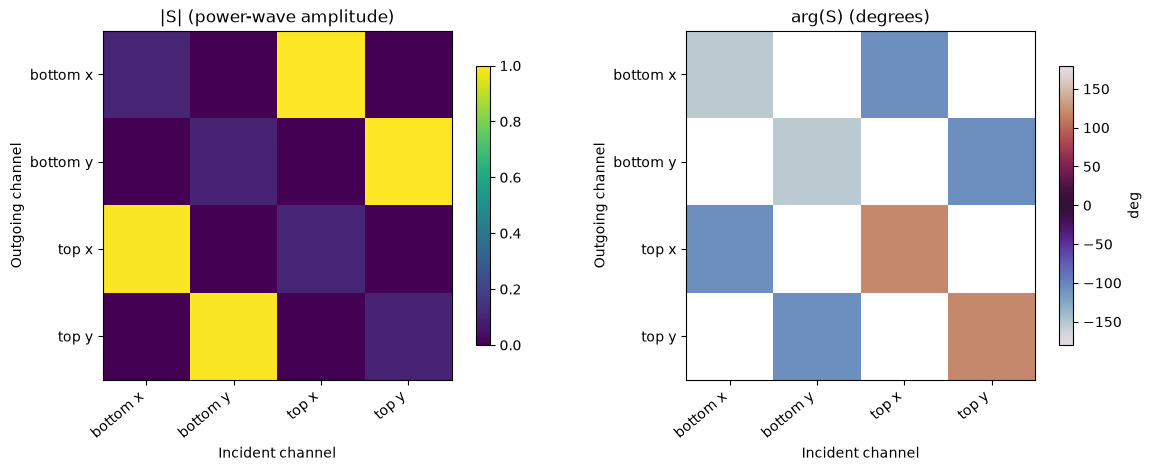

Phase masked where |S_ij| < 0.00997; these phases are ill-defined.
Diagnostics: {'reciprocity_max': 0.00466847852025254, 'unitarity_max': 0.0045950306880883085, 'passivity_lambda_max': 1.0036230356743392, 'worst_power_error': 0.0045950306880881975}


In [8]:
S_char = (np.asarray(fd['S_phase_aligned']) if fd is not None
          else np.asarray(rc['S']) if rc is not None else S_analytic)
S_base = (np.asarray(fd['S_flat_phase_aligned']) if fd is not None
          else np.asarray(rc_bare['S']) if rc is not None else S_analytic)
labels = ['bottom x','bottom y','top x','top y']
mag = np.abs(S_char)
threshold = max(1e-5, 0.01*mag.max())
phase_deg = np.ma.masked_where(mag < threshold, np.rad2deg(np.angle(S_char)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
im_mag = ax[0].imshow(mag, vmin=0, vmax=1, cmap='viridis')
im_phi = ax[1].imshow(phase_deg, vmin=-180, vmax=180, cmap='twilight')
for a, title in zip(ax, ('|S| (power-wave amplitude)', 'arg(S) (degrees)')):
    a.set(title=title, xlabel='Incident channel', ylabel='Outgoing channel',
          xticks=range(4), yticks=range(4))
    a.set_xticklabels(labels, rotation=40, ha='right')
    a.set_yticklabels(labels)
fig.colorbar(im_mag, ax=ax[0], shrink=.8)
fig.colorbar(im_phi, ax=ax[1], shrink=.8, label='deg')
plt.show()
print(f'Phase masked where |S_ij| < {threshold:.3g}; these phases are ill-defined.')
print('Diagnostics:', metrics(S_char))

### 7a. Reflection/transmission power budget

Sum the power-normalized outgoing channels for each individual incident port. For a passive, lossless device the reflection-plus-transmission sum should approach unity. Deviations are a **numerical/physical diagnostic**, not a phase correction.

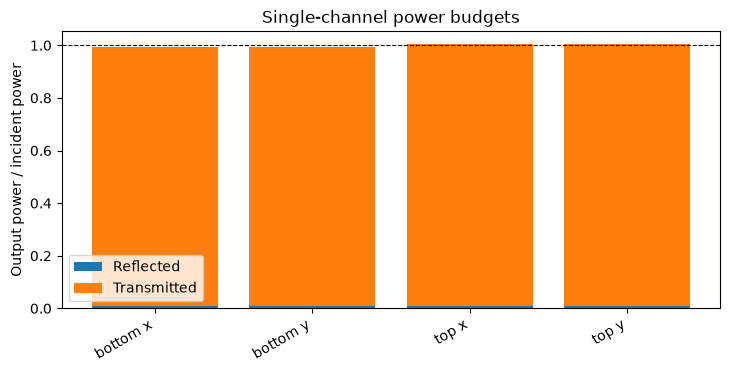

 bottom x: R=0.01035, T=0.98505, 1-R-T=+4.595e-03
 bottom y: R=0.01029, T=0.98512, 1-R-T=+4.592e-03
    top x: R=0.01033, T=0.99324, 1-R-T=-3.579e-03
    top y: R=0.01027, T=0.99331, 1-R-T=-3.583e-03


In [9]:
reflection = np.array([np.sum(abs(S_char[:2,j])**2) if j<2
                       else np.sum(abs(S_char[2:,j])**2) for j in range(4)])
transmission = np.array([np.sum(abs(S_char[2:,j])**2) if j<2
                         else np.sum(abs(S_char[:2,j])**2) for j in range(4)])
fig, ax = plt.subplots(figsize=(8.5,3.6))
ax.bar(labels, reflection, label='Reflected')
ax.bar(labels, transmission, bottom=reflection, label='Transmitted')
ax.axhline(1, ls='--', color='black', lw=.8)
ax.set(ylabel='Output power / incident power', title='Single-channel power budgets')
ax.legend()
plt.xticks(rotation=30, ha='right')
plt.show()
for label, r, t in zip(labels, reflection, transmission):
    print(f'{label:>9}: R={r:.5f}, T={t:.5f}, 1-R-T={1-r-t:+.3e}')

### 7b. Jones common phase and coherent channel phases

For a **nonsingular** Jones block $J$, a basis-consistent scalar phase convention is

$$\phi_{\det}(J)=\frac12\arg\det J\quad (\bmod\ \pi).$$

It corresponds to factoring out the determinant phase so that the residual matrix has a positive-real determinant; the square root necessarily leaves a **$\pi$ sign ambiguity**. Hence $\phi_{\det}$ is *not* by itself a unique $2\pi$-resolved global phase, and becomes unreliable as $\det J\to0$. We also report $\arg\operatorname{tr}J$ (a lab-basis-dependent, $2\pi$-resolved convention when the trace is nonzero). Neither alone tells every incident polarization's optical phase.

The directly observable complex scalar for an input Jones vector $|u\rangle$ and analyzer $|v\rangle$ is $\langle v|J|u\rangle$; its **full $2\pi$ phase** is printed below. For wavefront design, specify which input and output states or target matrix is being optimized rather than dropping a Jones-global phase.

In [10]:
def phase_deg_of(z, eps=1e-10):
    return float(np.rad2deg(np.angle(z))) if abs(z) > eps else float('nan')

def phase_diagnostics(J, name):
    J = np.asarray(J, complex)
    scale = np.linalg.norm(J, ord='fro')**2
    determinant = np.linalg.det(J)
    phi_det = phase_deg_of(determinant)/2 if abs(determinant)>1e-8*scale else float('nan')
    phi_trace = phase_deg_of(np.trace(J), eps=1e-8*np.linalg.norm(J,ord='fro'))
    print(f'{name}:  φ_det={phi_det:+.2f}° (mod 180°), '
          f'φ_trace={phi_trace:+.2f}° (mod 360°); '
          f'|det J|={abs(determinant):.5g}; '
          f'σ(J)={np.round(np.linalg.svd(J,compute_uv=False),5)}')
    for pol, u in [('x',np.array([1,0])), ('y',np.array([0,1])),
                   ('+45°',np.array([1,1])/np.sqrt(2)),
                   ('R-circ',np.array([1,-1j])/np.sqrt(2))]:
        val = np.vdot(u, J @ u)
        print(f'   {pol:>6} → same analyzer: |a|={abs(val):.5f}, arg(a)={phase_deg_of(val):+.2f}°')
    return phi_det

for name, J in [('T₂₁ bottom → top', S_char[2:,:2]),
                ('T₁₂ top → bottom', S_char[:2,2:]),
                ('R₁₁ bottom', S_char[:2,:2]),
                ('R₂₂ top', S_char[2:,2:])]:
    phase_diagnostics(J, name)

T₂₁ bottom → top:  φ_det=+73.08° (mod 180°), φ_trace=-106.92° (mod 360°); |det J|=0.98509; σ(J)=[0.99254 0.99249]
        x → same analyzer: |a|=0.99250, arg(a)=-106.96°
        y → same analyzer: |a|=0.99253, arg(a)=-106.88°
     +45° → same analyzer: |a|=0.99250, arg(a)=-106.97°
   R-circ → same analyzer: |a|=0.99251, arg(a)=-106.92°
T₁₂ top → bottom:  φ_det=+73.20° (mod 180°), φ_trace=-106.80° (mod 360°); |det J|=0.99328; σ(J)=[0.99666 0.99661]
        x → same analyzer: |a|=0.99662, arg(a)=-106.84°
        y → same analyzer: |a|=0.99665, arg(a)=-106.76°
     +45° → same analyzer: |a|=0.99662, arg(a)=-106.84°
   R-circ → same analyzer: |a|=0.99663, arg(a)=-106.80°
R₁₁ bottom:  φ_det=+26.68° (mod 180°), φ_trace=-153.32° (mod 360°); |det J|=0.010321; σ(J)=[0.10183 0.10136]
        x → same analyzer: |a|=0.10176, arg(a)=-153.39°
        y → same analyzer: |a|=0.10143, arg(a)=-153.26°
     +45° → same analyzer: |a|=0.10176, arg(a)=-153.64°
   R-circ → same analyzer: |a|=0.10159, arg(a)=

### 7c. Physical port planes versus device faces

The default scattering matrix is referenced to the **homogeneous monitor planes**. We can also re-express that *same* solved $S$ at $z=0$ and $z=h$ using known homogeneous propagation factors. **This is not stripping the physical propagation phase acquired in the fins or coupled cavity.** Both forms are retained, and changing reference planes does not require a new Maxwell solve.

Comparing a finned cell with a bare interface at *identical* reference planes is useful for relative phase engineering, but we never replace the actual complex response by that comparison.

In [11]:
S_faces = change_reference_planes(S_char, cfg, ports, (0., cfg.height))
S_base_faces = change_reference_planes(S_base, cfg, ports, (0., cfg.height))
print('Monitor planes:', ports, 'µm; device-face planes:', (0., cfg.height), 'µm')
print('Both complex matrices retained: S_char (monitor) and S_faces (faces).')
for tag, S_sample, S_ref in [('Monitor planes',S_char,S_base),
                             ('Device faces',S_faces,S_base_faces)]:
    print('\n' + tag)
    tf, tb = S_sample[2:,:2], S_sample[:2,2:]
    phase_diagnostics(tf, 'T₂₁')
    phase_diagnostics(tb, 'T₁₂')
    for pol, col in [('x',0), ('y',1)]:
        obj, bare = tf[col,col], S_ref[2+col,col]
        # Relative phase is reported, not removed from the full S matrix.
        relative = phase_deg_of(obj*np.conj(bare))
        print(f'  co-pol {pol}: arg(T₂₁)={phase_deg_of(obj):+.2f}°, '
              f'fin-minus-flat={relative:+.2f}°')

# Determinant phases are only meaningful on non-singular Jones blocks.
T_fin, T_flat = S_faces[2:,:2], S_base_faces[2:,:2]
det_ratio = np.linalg.det(T_fin)*np.conj(np.linalg.det(T_flat))
if min(abs(np.linalg.det(T_fin)),abs(np.linalg.det(T_flat))) > 1e-8:
    print('\nFin-vs-flat determinant phase:', 0.5*phase_deg_of(det_ratio),
          'degrees (modulo 180°, NOT an absolute 2π phase)')

Monitor planes: (-0.53, 0.8700000000000001) µm; device-face planes: (0.0, 0.35) µm
Both complex matrices retained: S_char (monitor) and S_faces (faces).

Monitor planes
T₂₁:  φ_det=+73.08° (mod 180°), φ_trace=-106.92° (mod 360°); |det J|=0.98509; σ(J)=[0.99254 0.99249]
        x → same analyzer: |a|=0.99250, arg(a)=-106.96°
        y → same analyzer: |a|=0.99253, arg(a)=-106.88°
     +45° → same analyzer: |a|=0.99250, arg(a)=-106.97°
   R-circ → same analyzer: |a|=0.99251, arg(a)=-106.92°
T₁₂:  φ_det=+73.20° (mod 180°), φ_trace=-106.80° (mod 360°); |det J|=0.99328; σ(J)=[0.99666 0.99661]
        x → same analyzer: |a|=0.99662, arg(a)=-106.84°
        y → same analyzer: |a|=0.99665, arg(a)=-106.76°
     +45° → same analyzer: |a|=0.99662, arg(a)=-106.84°
   R-circ → same analyzer: |a|=0.99663, arg(a)=-106.80°
  co-pol x: arg(T₂₁)=-106.96°, fin-minus-flat=+38.20°
  co-pol y: arg(T₂₁)=-106.88°, fin-minus-flat=+38.28°

Device faces
T₂₁:  φ_det=+57.27° (mod 180°), φ_trace=-122.73° (mod 360°)

### 7d. Save the complete complex response for later optimization

The `.npz` file stores the **unmodified complex phase information** at both reference-plane choices, plus the bare-interface benchmark. Characterization can be repeated from these arrays without solving Maxwell's equations again.

In [12]:
scattering_file = OUT / 'twofin_complex_scattering.npz'
np.savez_compressed(scattering_file,
    S_monitor=S_char, S_device_faces=S_faces,
    S_flat_monitor=S_base, S_flat_device_faces=S_base_faces,
    T21_monitor=S_char[2:,:2], T21_device_faces=S_faces[2:,:2],
    T12_monitor=S_char[:2,2:], T12_device_faces=S_faces[:2,2:],
    monitor_z_um=np.asarray(ports), face_z_um=np.array([0.,cfg.height]),
    wavelength_um=cfg.wavelength, channel_labels=np.asarray(labels))
print('Saved full complex S and Jones blocks:', scattering_file.resolve())

Saved full complex S and Jones blocks: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/results/twofin_complex_scattering.npz


## 8. Eigenpolarizations and Poincaré spheres

Each $2\times2$ transmission/reflection block has its own polarization eigenvectors. We report their **complex eigenvalues, phase, and normalized Stokes vectors**. The complete $4\times4$ scattering eigenvectors are coherent two-sided channels; they do *not* each correspond to a single Poincaré point.


 R₁₁
  eigenstate 1: λ=-0.091207-0.045204j, |λ|=0.10179, phase=-153.64°, Stokes=[ 1.       0.27629  0.9413  -0.19396]
  eigenstate 2: λ=-0.090351-0.046013j, |λ|=0.10139, phase=-153.01°, Stokes=[ 1.      -0.28064 -0.9393  -0.19737]

 T₂₁
  eigenstate 1: λ=-0.287961-0.949844j, |λ|=0.99253, phase=-106.87°, Stokes=[ 1.      -0.68174 -0.72959 -0.05414]
  eigenstate 2: λ=-0.289900-0.949213j, |λ|=0.99250, phase=-106.98°, Stokes=[1.      0.68186 0.72854 0.06553]

 T₁₂
  eigenstate 1: λ=-0.287049-0.954426j, |λ|=0.99666, phase=-106.74°, Stokes=[ 1.      -0.68091 -0.72967  0.06274]
  eigenstate 2: λ=-0.288999-0.953788j, |λ|=0.99661, phase=-106.86°, Stokes=[ 1.       0.67872  0.73202 -0.05903]

 R₂₂
  eigenstate 1: λ=-0.050750+0.088103j, |λ|=0.10167, phase=+119.94°, Stokes=[1.      0.10196 0.93154 0.34906]
  eigenstate 2: λ=-0.049914+0.088169j, |λ|=0.10132, phase=+119.52°, Stokes=[ 1.      -0.09951 -0.93388  0.34346]


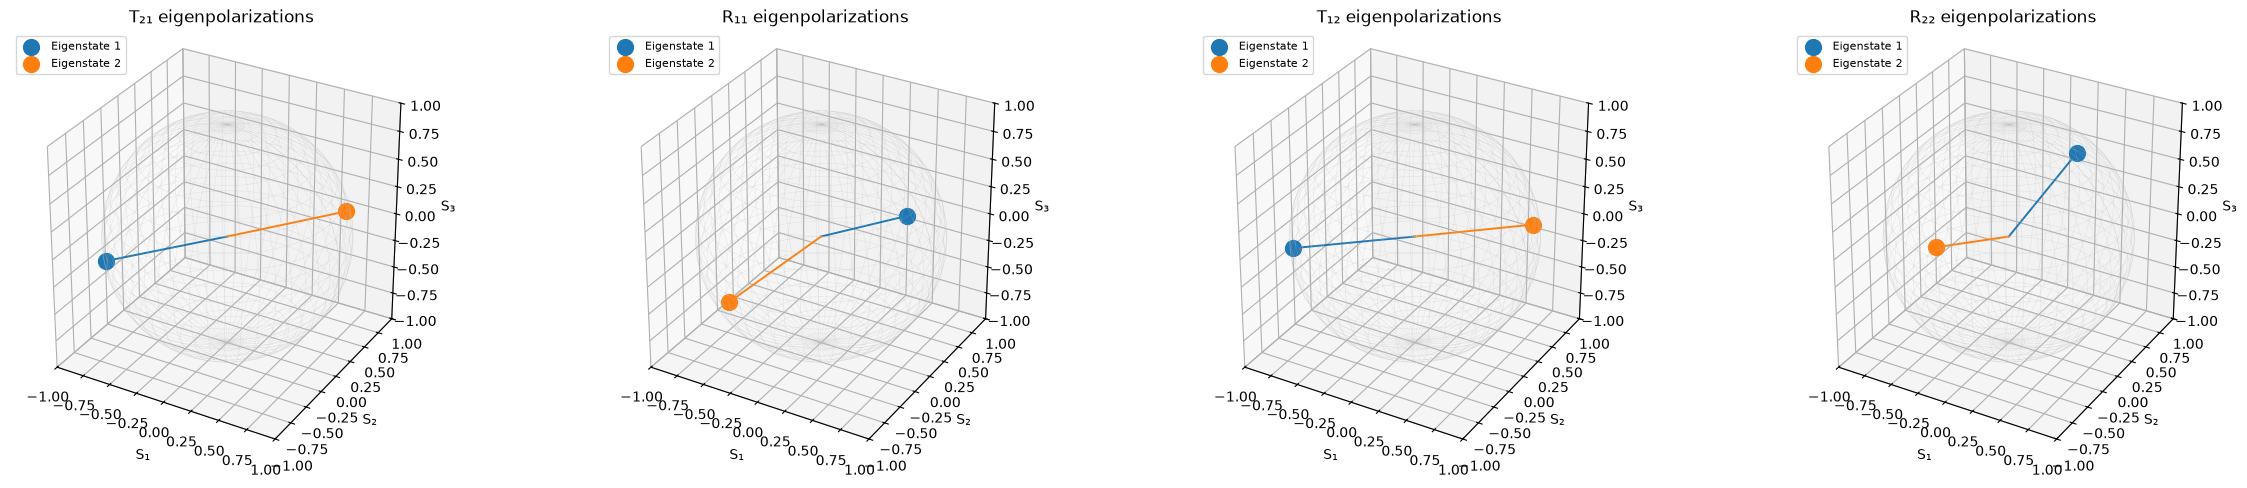

In [13]:
S_display = fd['S_phase_aligned'] if fd is not None else (rc['S'] if rc is not None else S_analytic)
print_polarization_modes(S_display)
fig = plot_poincare(S_display,blocks=('T₂₁','R₁₁','T₁₂','R₂₂'))
plt.show()

## 9. Optional: numerical convergence

The initial targets are **trends**, not arbitrary accuracy labels. Improve FDTD spacing and RCWA Fourier order independently; the reference and inter-solver complex $S$ comparisons decide whether we trust any phase result.

In [14]:
if RUN_CONVERGENCE:
    # RCWA order convergence; increase only if device memory allows.
    previous = None
    for order in (3,4,5):
        test = rcwa_solve(cfg,replace(rc_settings,order=order),ports=ports)
        if previous is not None:
            print(f'RCWA order {order-1} -> {order}: max complex delta =',
                  np.max(abs(test['S']-previous['S'])))
        previous=test
    # FDTD convergence: uses the SAME monitor positions up to grid snapping.
    f20 = fdtd_solve(cfg,replace(fd_settings,dx_nm=20.),cache=OUT)
    f10 = fdtd_solve(cfg,replace(fd_settings,dx_nm=10.),cache=OUT)
    s10_aligned = change_reference_planes(f10['S_phase_aligned'],cfg,f10['ports'],f20['ports'])
    print('FDTD dx 20 -> 10 nm, ports aligned: max complex delta =',
          np.max(abs(s10_aligned-f20['S_phase_aligned'])))

RCWA order 3 -> 4: max complex delta = 0.0153470559850672
RCWA order 4 -> 5: max complex delta = 0.007782645379578457
FDTD reference / bottom / x
FDTD reference / bottom / y
FDTD reference / top / x
FDTD reference / top / y
FDTD two-fin / bottom / x
FDTD two-fin / bottom / y
FDTD two-fin / top / x
FDTD two-fin / top / y
FDTD bare-interface continuum Fresnel error: 0.007938151967293266
FDTD bare-interface Yee-phase Fresnel error: 0.0006024760130753137
FDTD structure validation: {'reciprocity_max': 0.0019052312024674899, 'unitarity_max': 0.0005488296488789235, 'passivity_lambda_max': 0.9999504335506911, 'worst_power_error': 0.0005488296488789235}
FDTD dx 20 -> 10 nm, ports aligned: max complex delta = 0.07038126364407722


## 10. Optional: eigenpolarization transport under rigid rotation

The two-fin orientation is a physical parameter, not an FDTD source polarization. Track the eigenvector by **overlap**, not by instantaneous eigenvalue sorting. The discrete Pancharatnam (Bargmann) product measures the kinematic geometric phase of the Stokes path closed by a shortest geodesic. It is **not automatically equal to a cross-polarized scattering PB phase**. Watch for near-degenerate eigenvalues where the branch becomes ill-defined.

Minimum eigenvalue separation: 0.011668245792730677
Kinematic Pancharatnam phase (deg): -0.09224059218497979


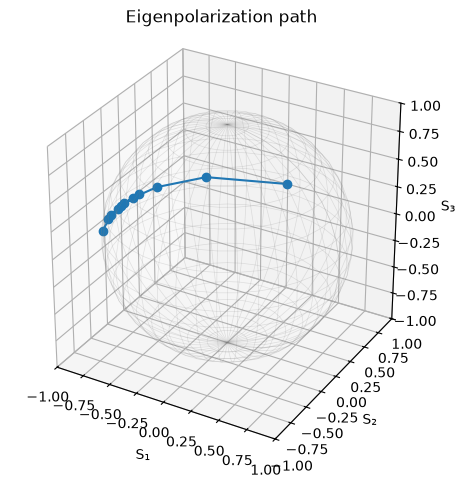

In [15]:
if RUN_TRANSPORT:
    angles = np.linspace(0,75,11)
    matrices = [rcwa_solve(replace(cfg,global_deg=float(angle)),rc_settings)['S']
                for angle in angles]
    path,gaps = eigenstate_path(matrices)
    print('Minimum eigenvalue separation:',gaps.min())
    print('Kinematic Pancharatnam phase (deg):',np.rad2deg(pancharatnam_phase(path)))
    fig=plot_path(path); plt.show()

## 11. Tests, performance and next engineering step

Run `python -m pytest -q tests` for analytic/geometry checks (ensures pytest uses this environment's Python). We **do not** claim end-to-end electromagnetic validation until numerical Fresnel, reciprocity, passivity, FDTD/RCWA complex comparison, and convergence tests run on your RTX A6000.

Possible future speed-up: profile the existing PyTorch FDTD update kernels with `torch.profiler`, then fuse only demonstrably dominant kernels (e.g., in Triton). This is intentionally separate from scattering correctness and not enabled here.

**Numerical warning:** because FDTD uses scalar subpixel fractions rather than a full anisotropic Yee-tensor homogenization, near-resonant eigenvectors and small phase differences still require careful resolution/convergence checks.

In [16]:
# Optional CUDA kernel profiling; leaves Maxwell equations unchanged.
RUN_PROFILE = False
if RUN_PROFILE:
    from engine_fdtd import profile_gpu_steps
    print(profile_gpu_steps(cfg,fd_settings,steps=30))

print('Generated GDS:', (OUT/'twofin_unit_cell.gds').resolve())
print('Validation checks live in tests/test_engine.py')
print('Notebook complete; full complex scattering phases have been preserved.')

Generated GDS: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/results/twofin_unit_cell.gds
Validation checks live in tests/test_engine.py
Notebook complete; full complex scattering phases have been preserved.


## Optional: independent hard-edge verification of inverse-design geometry

This notebook remains the **lossless forward-solver validation** reference. The EP search uses passive absorption and therefore **cannot be checked by the current real-permittivity FDTD engine**. The following optional check loads a candidate from the inverse-design notebook, reconstructs the two independent fin polygons and runs the **legacy non-differentiable RCWA** backend. It does not silently re-use the differentiable RCWA implementation. A validated EP additionally requires Fourier-order convergence and Jordan/encircling diagnostics.

In [17]:
RUN_CHECK_EP_CANDIDATE=False   # Extra RCWA; lossy designs cannot use current FDTD
if RUN_CHECK_EP_CANDIDATE:
    from engine_inverse import load_checkpoint, candidate_to_config, FIXED_PORTS
    from engine_ep import print_ep_report
    candidate = load_checkpoint(Path('../02_twofin_ep_inverse/results/ep_design/best_gradient_candidate.npz'))
    physical = candidate_to_config(cfg,candidate['params'])
    fig=draw_geometry(physical)
    plt.show()
    for order in (5,7,9):
        result=rcwa_solve(physical,replace(rc_settings,order=order),ports=FIXED_PORTS)
        print_ep_report(result['S'],label=f'Independent hard-edge RCWA order={order}')
else:
    print('EP-candidate RCWA validation disabled by default.')

EP-candidate RCWA validation disabled by default.
